# Relativistic Redshift Estimation & Celestial Classification Using Spectral Vector Spaces
**Team:** Arya (Phase 1) • Sakshi (Phase 2) • Ritu (Phase 3) • Somil (Phase 4)  
**Dataset:** Sloan Digital Sky Survey (SDSS17 — `../data/processed/sdss_clean.csv`)

## Unifying Research Question
Using only **5 raw photometric brightness readings** ($u, g, r, i, z$) from a telescope, can pure mathematics tell us both **what** a celestial object is (Star, Galaxy, or Quasar) and **how fast** it is receding from Earth as a fraction of the speed of light ($\beta = v/c$)?

## Pipeline Architecture
1. **Phase 1 — Relativity Math & Data Verification (Arya):** Symbolically invert Einstein's Relativistic Doppler equation in SymPy and verify the cleaned SDSS17 dataset.
2. **Phase 2 — 5D Spectral Space & PCA/SVD (Sakshi):** Standardize the 5D light vectors, compute the $5 \times 5$ covariance matrix, and compress to 2D via SVD/PCA.
3. **Phase 3 — Unsupervised Cosmic Clustering (Ritu):** Run K-Means ($k=3$) on the 2D PCA coordinates without labels and measure alignment against true cosmic classes.
4. **Phase 4 — Relativistic Redshift & Velocity Prediction (Somil):** Train Linear Regression on the 5 light bands to predict redshift ($z$) and convert predictions into relativistic velocities ($\beta = v/c$).

In [6]:
import subprocess
import sys
import time
from pathlib import Path

NOTEBOOKS = [
    "01_relativity_and_cleaning.ipynb",
    "02_spectral_pca.ipynb",
    "03_kmeans_clustering.ipynb",
    "04_redshift_regression.ipynb",
]

print("Starting End-to-End Relativistic Redshift Pipeline...\n")
total_start = time.time()

for i, nb_name in enumerate(NOTEBOOKS, start=1):
    nb_path = Path(nb_name)
    if not nb_path.exists():
        raise FileNotFoundError(f"Missing notebook: {nb_path.resolve()}")

    print(f"[{i}/{len(NOTEBOOKS)}] Executing {nb_name} ...")
    step_start = time.time()

    result = subprocess.run(
        [
            sys.executable, "-m", "jupyter", "nbconvert",
            "--to", "notebook",
            "--execute",
            "--inplace",
            str(nb_path),
        ],
        capture_output=True,
        text=True,
    )

    elapsed = time.time() - step_start
    if result.returncode != 0:
        print(f"FAILED on {nb_name} after {elapsed:.1f}s:\n")
        print(result.stderr)
        raise RuntimeError(f"Pipeline halted at {nb_name}")

    print(f"    ✓ Completed {nb_name} in {elapsed:.1f}s\n")

print(f"All 4 phases completed cleanly in {time.time() - total_start:.1f}s!")

Starting End-to-End Relativistic Redshift Pipeline...

[1/4] Executing 01_relativity_and_cleaning.ipynb ...
FAILED on 01_relativity_and_cleaning.ipynb after 14.7s:

[NbConvertApp] Converting notebook 01_relativity_and_cleaning.ipynb to notebook
C:\Users\bhara\anaconda3\Lib\site-packages\zmq\_future.py:718: RuntimeWarning: Proactor event loop does not implement add_reader family of methods required for zmq. Registering an additional selector thread for add_reader support via tornado. Use `asyncio.set_event_loop_policy(WindowsSelectorEventLoopPolicy())` to avoid this warning.
  self._get_loop()
Traceback (most recent call last):
  File "C:\Users\bhara\anaconda3\Scripts\jupyter-nbconvert-script.py", line 10, in <module>
    sys.exit(main())
             ~~~~^^
  File "C:\Users\bhara\anaconda3\Lib\site-packages\jupyter_core\application.py", line 284, in launch_instance
    super().launch_instance(argv=argv, **kwargs)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\bhara\a

RuntimeError: Pipeline halted at 01_relativity_and_cleaning.ipynb

## Generated Pipeline Figures (`../figures/`)
Below are all 300 DPI figures automatically generated by Phases 1–4, displayed together for quick inspection and viva walkthrough.

Displaying 5 exported figures:



### `04_gradient_descent_and_upgraded_fit.png`

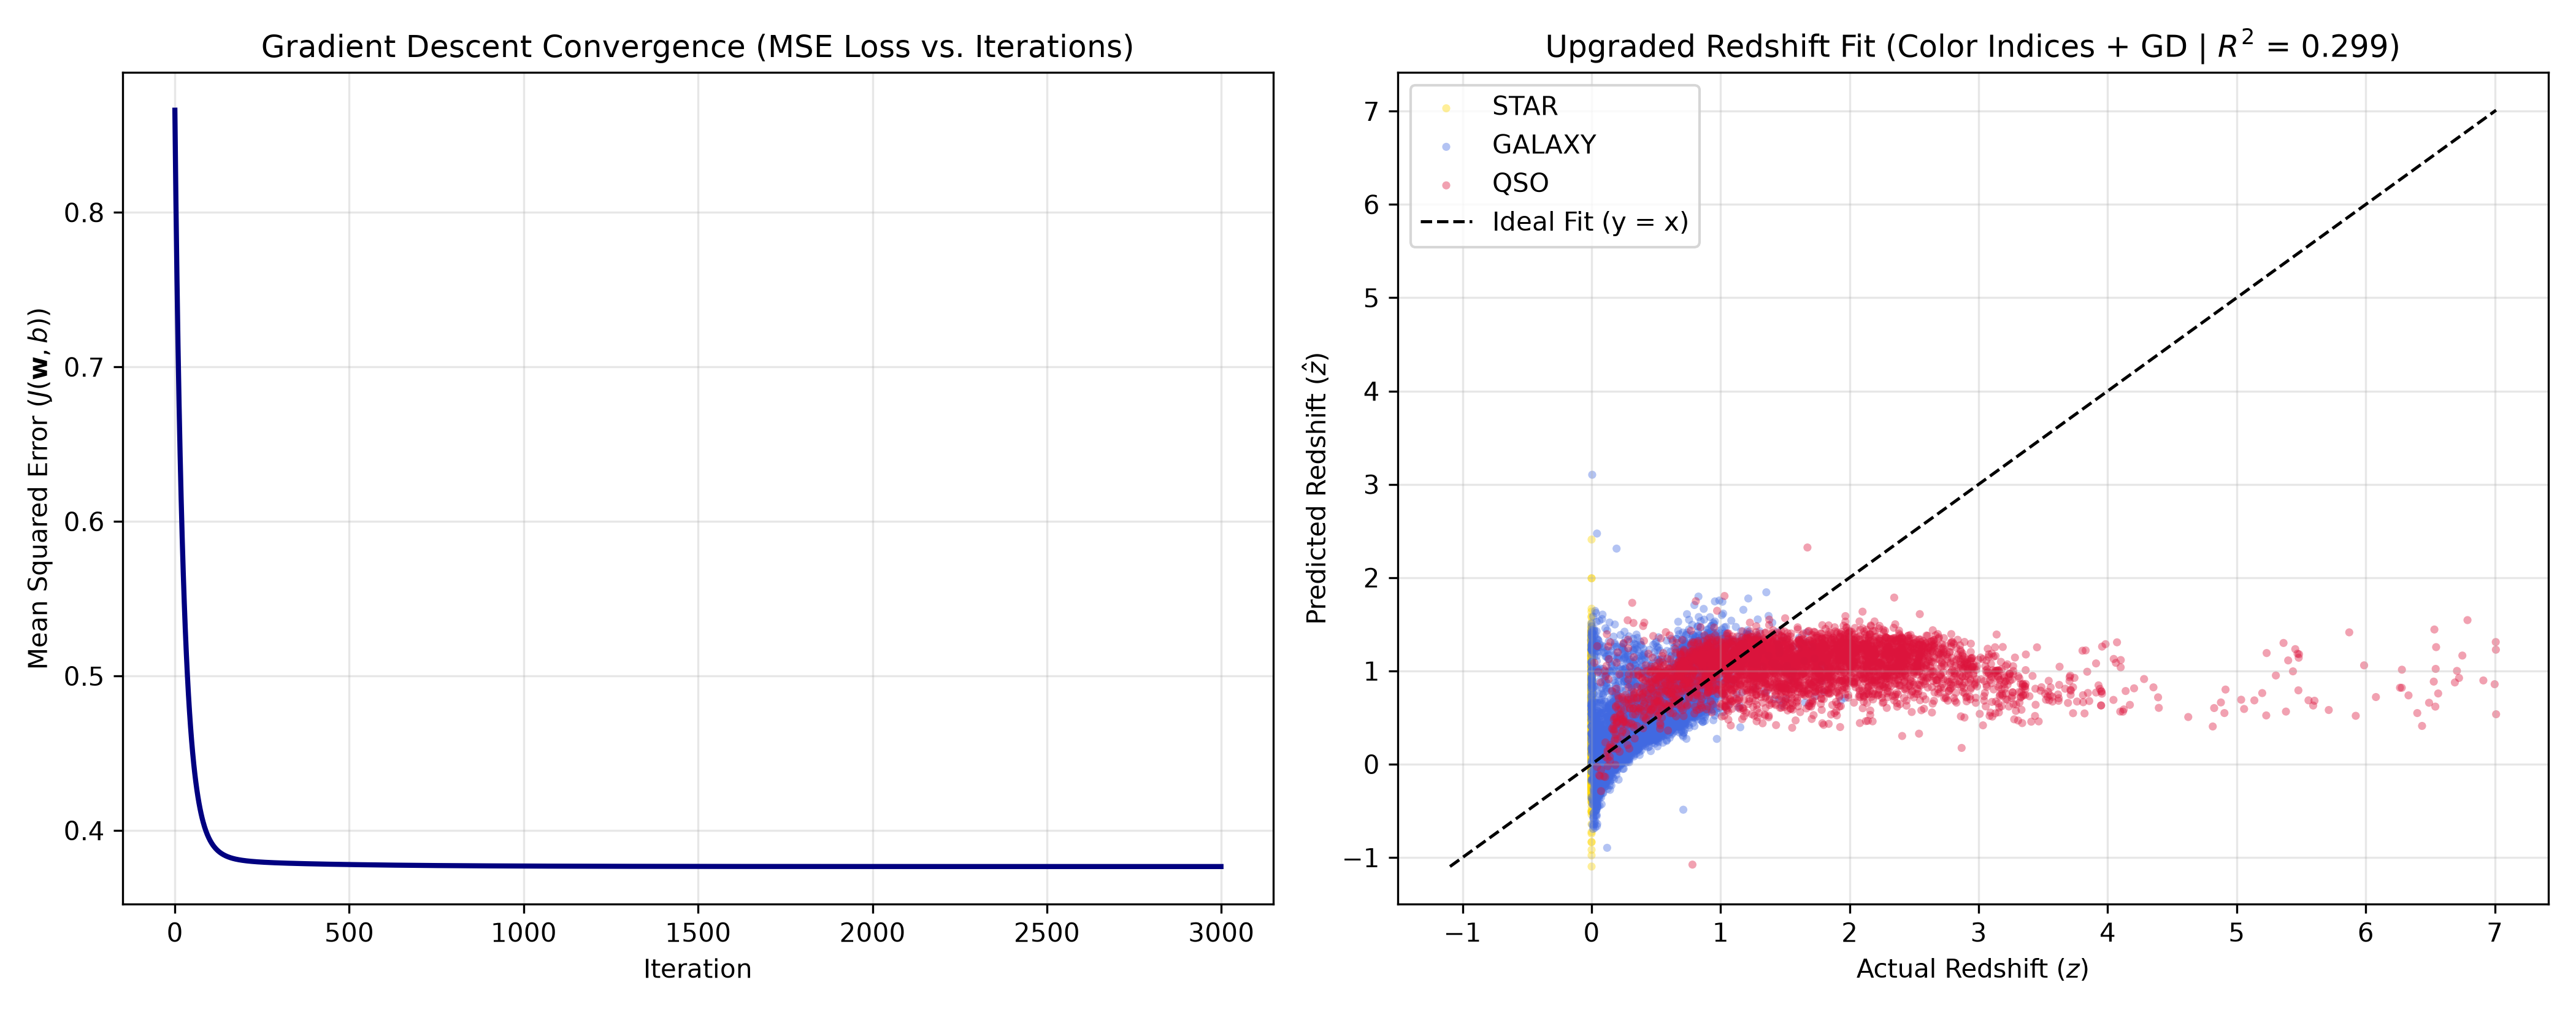

### `04_redshift_predicted_vs_actual.png`

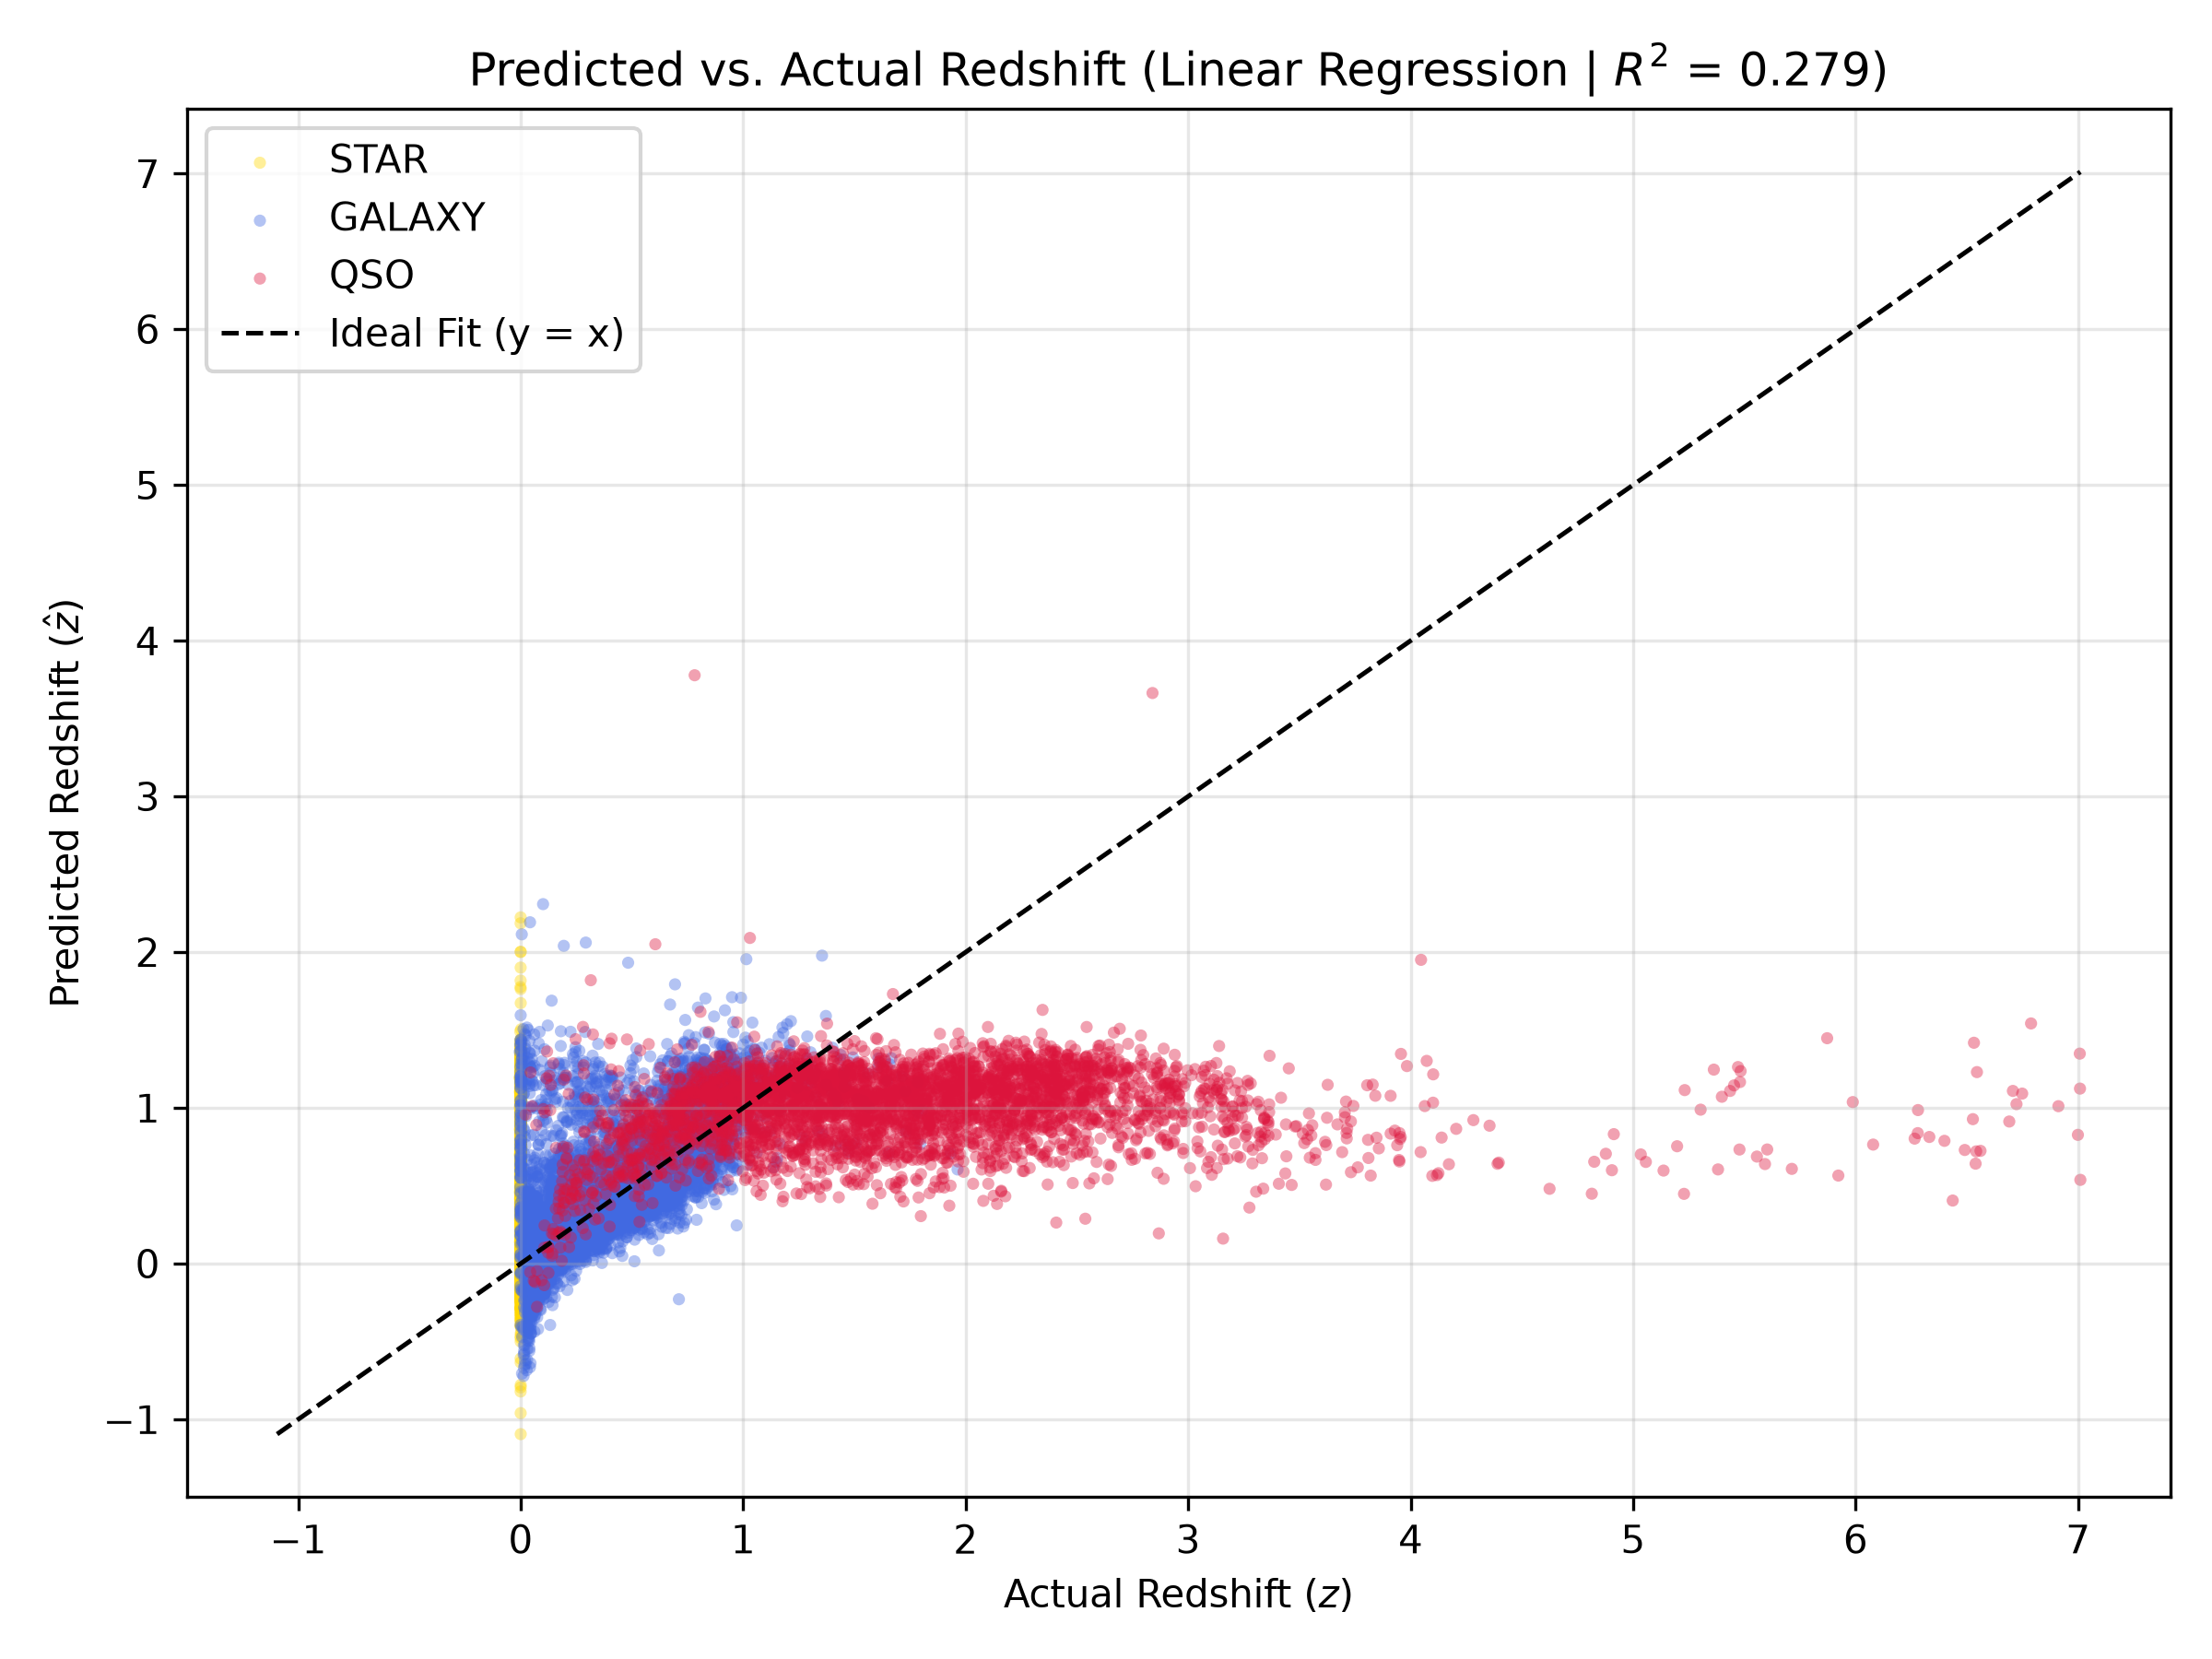

### `04_velocity_predicted_vs_actual.png`

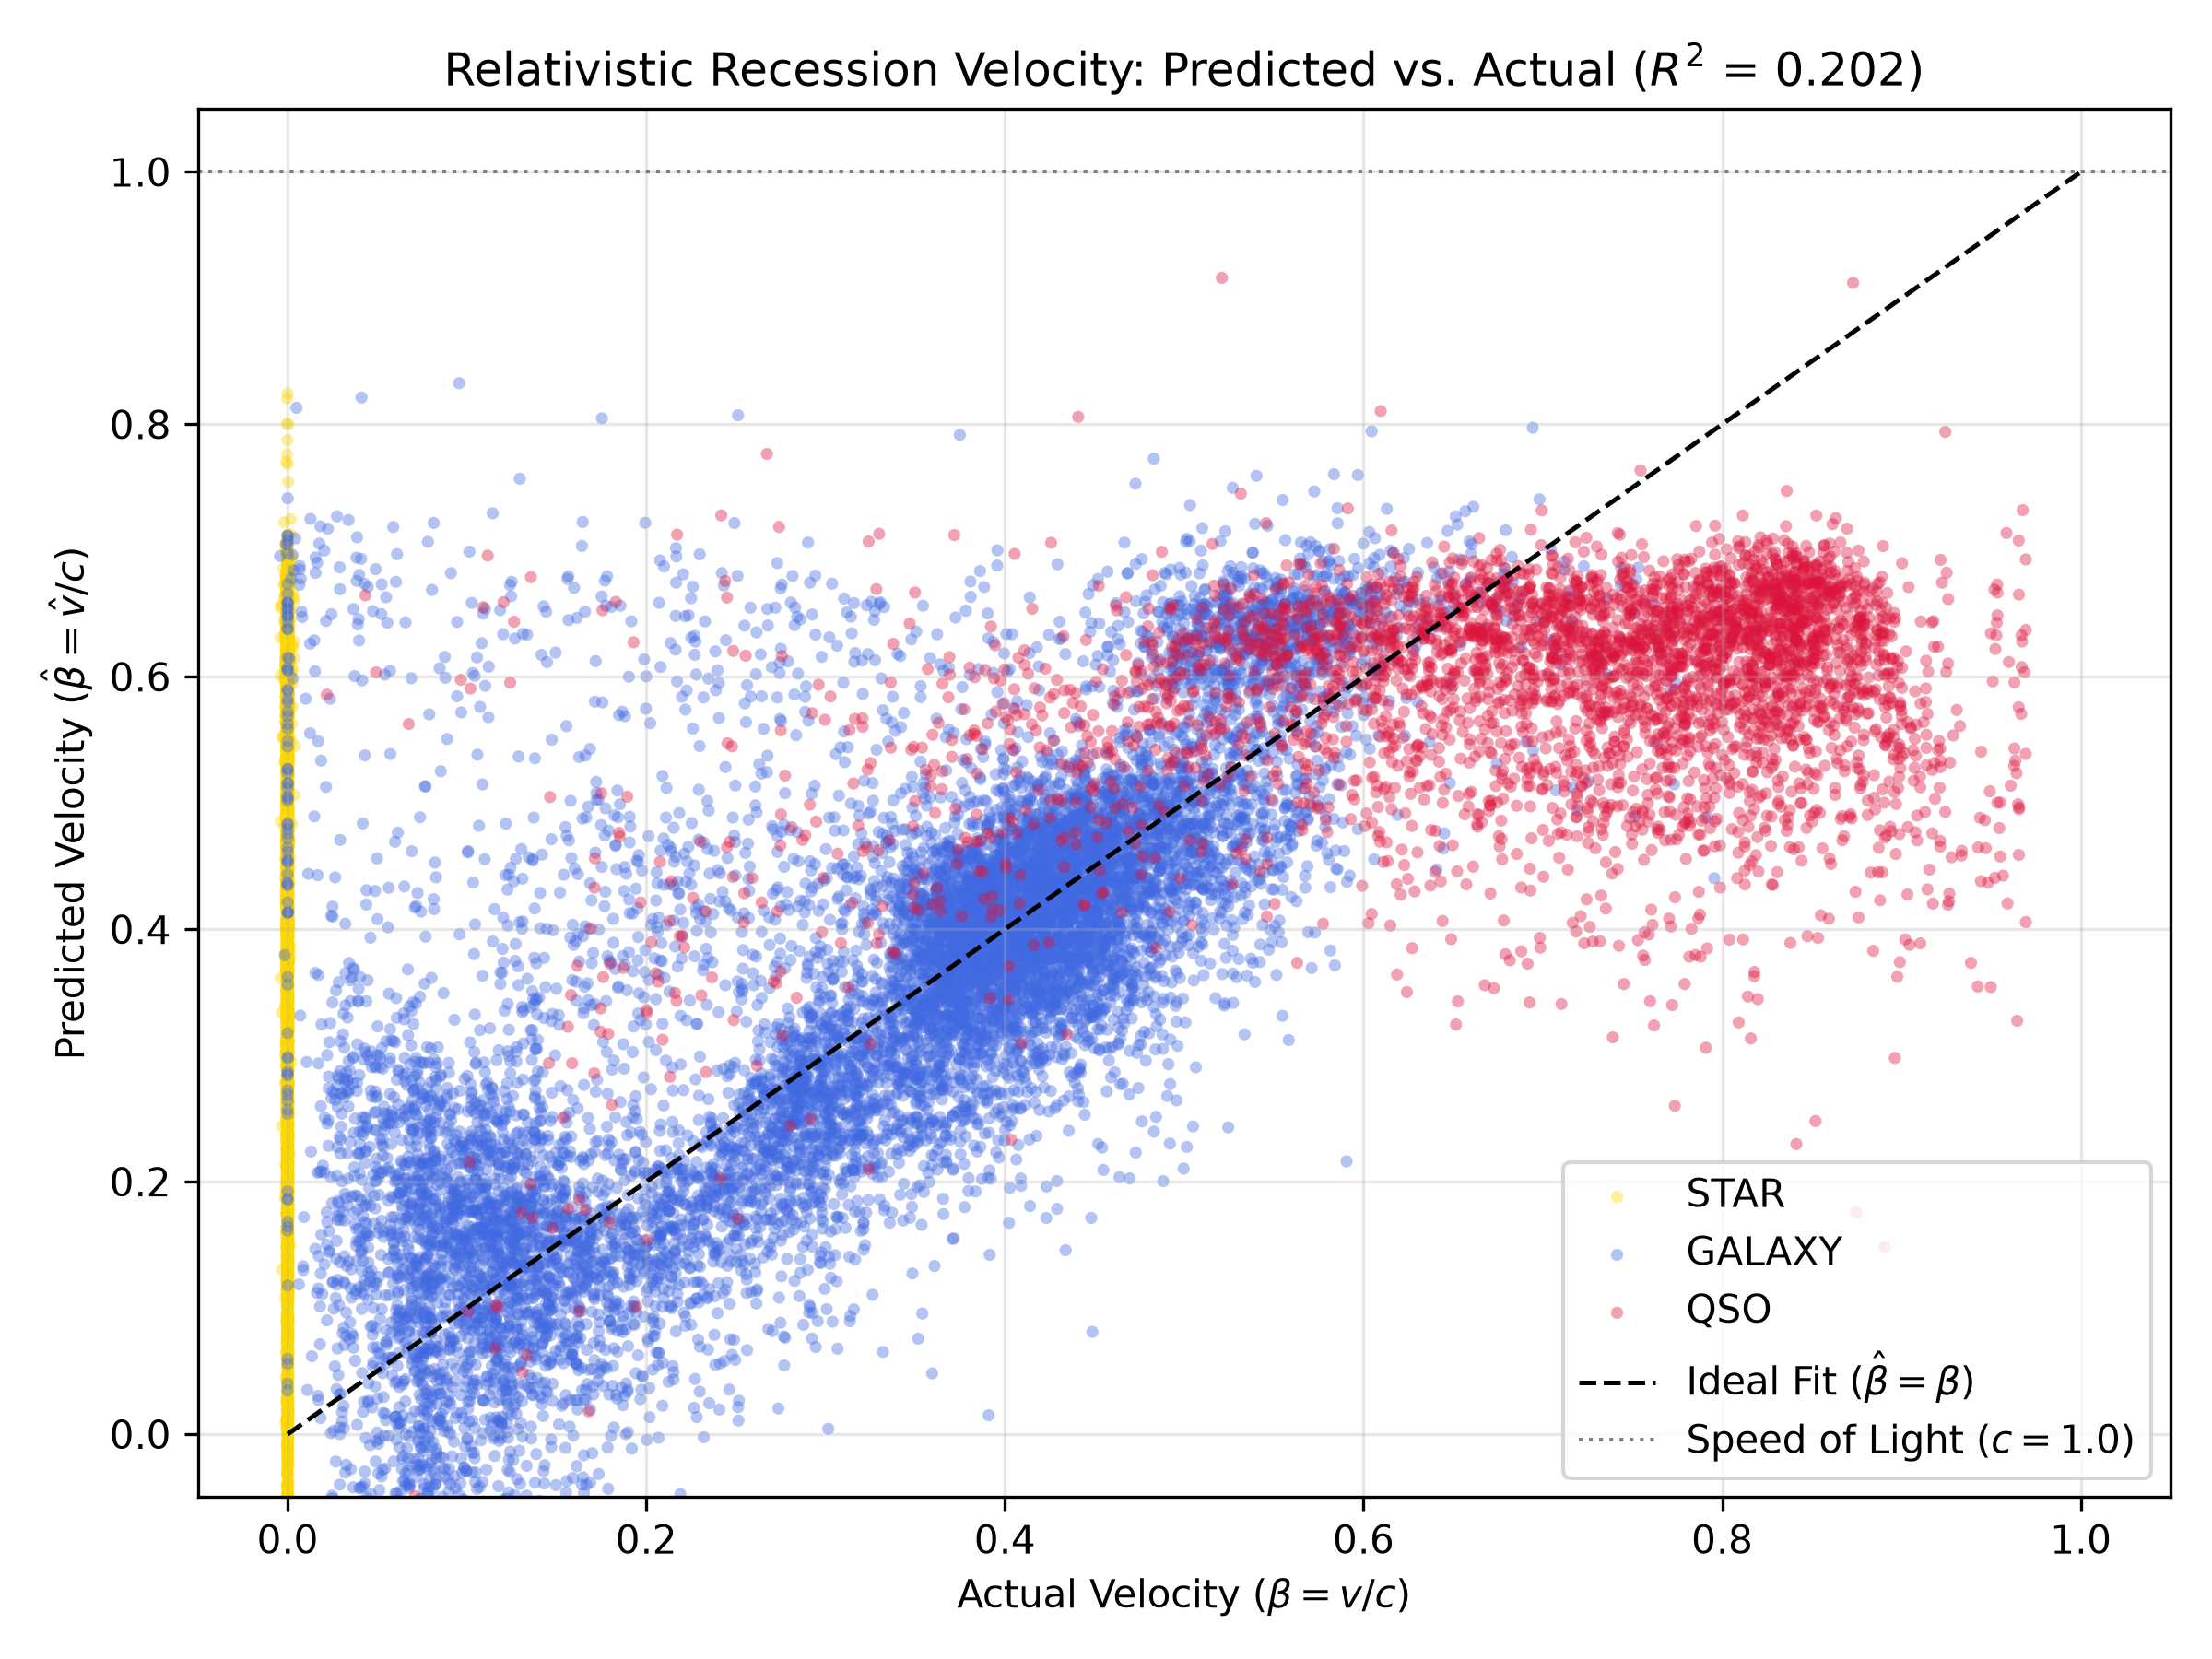

### `kmeans_cluster_comparison.png`

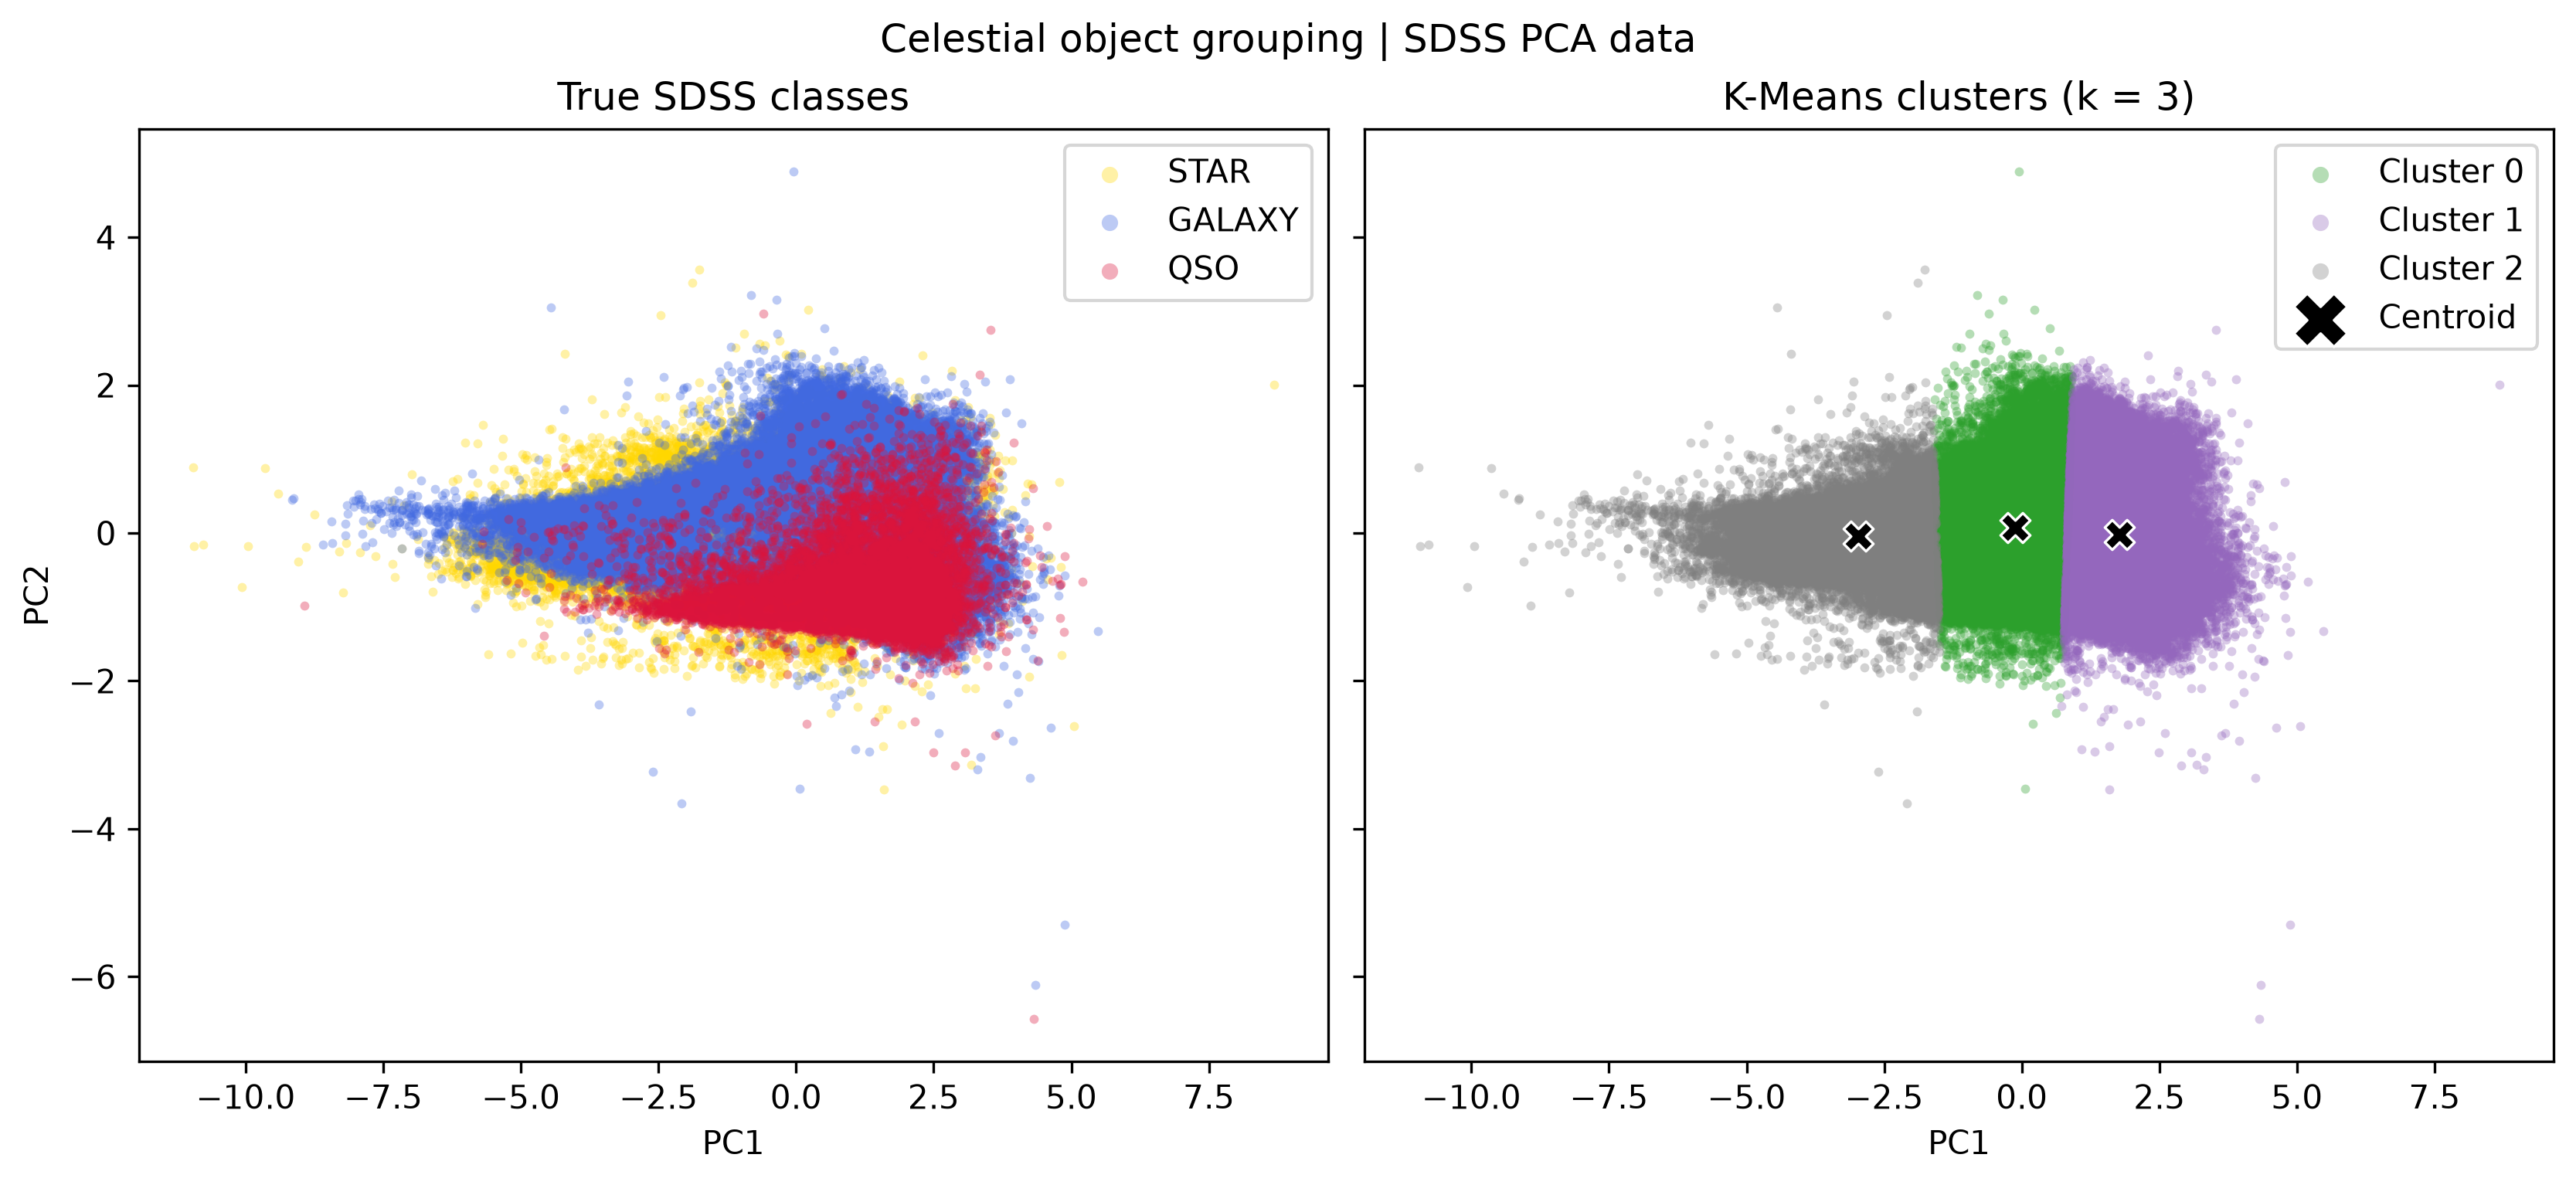

### `pca_spectral_space.png`

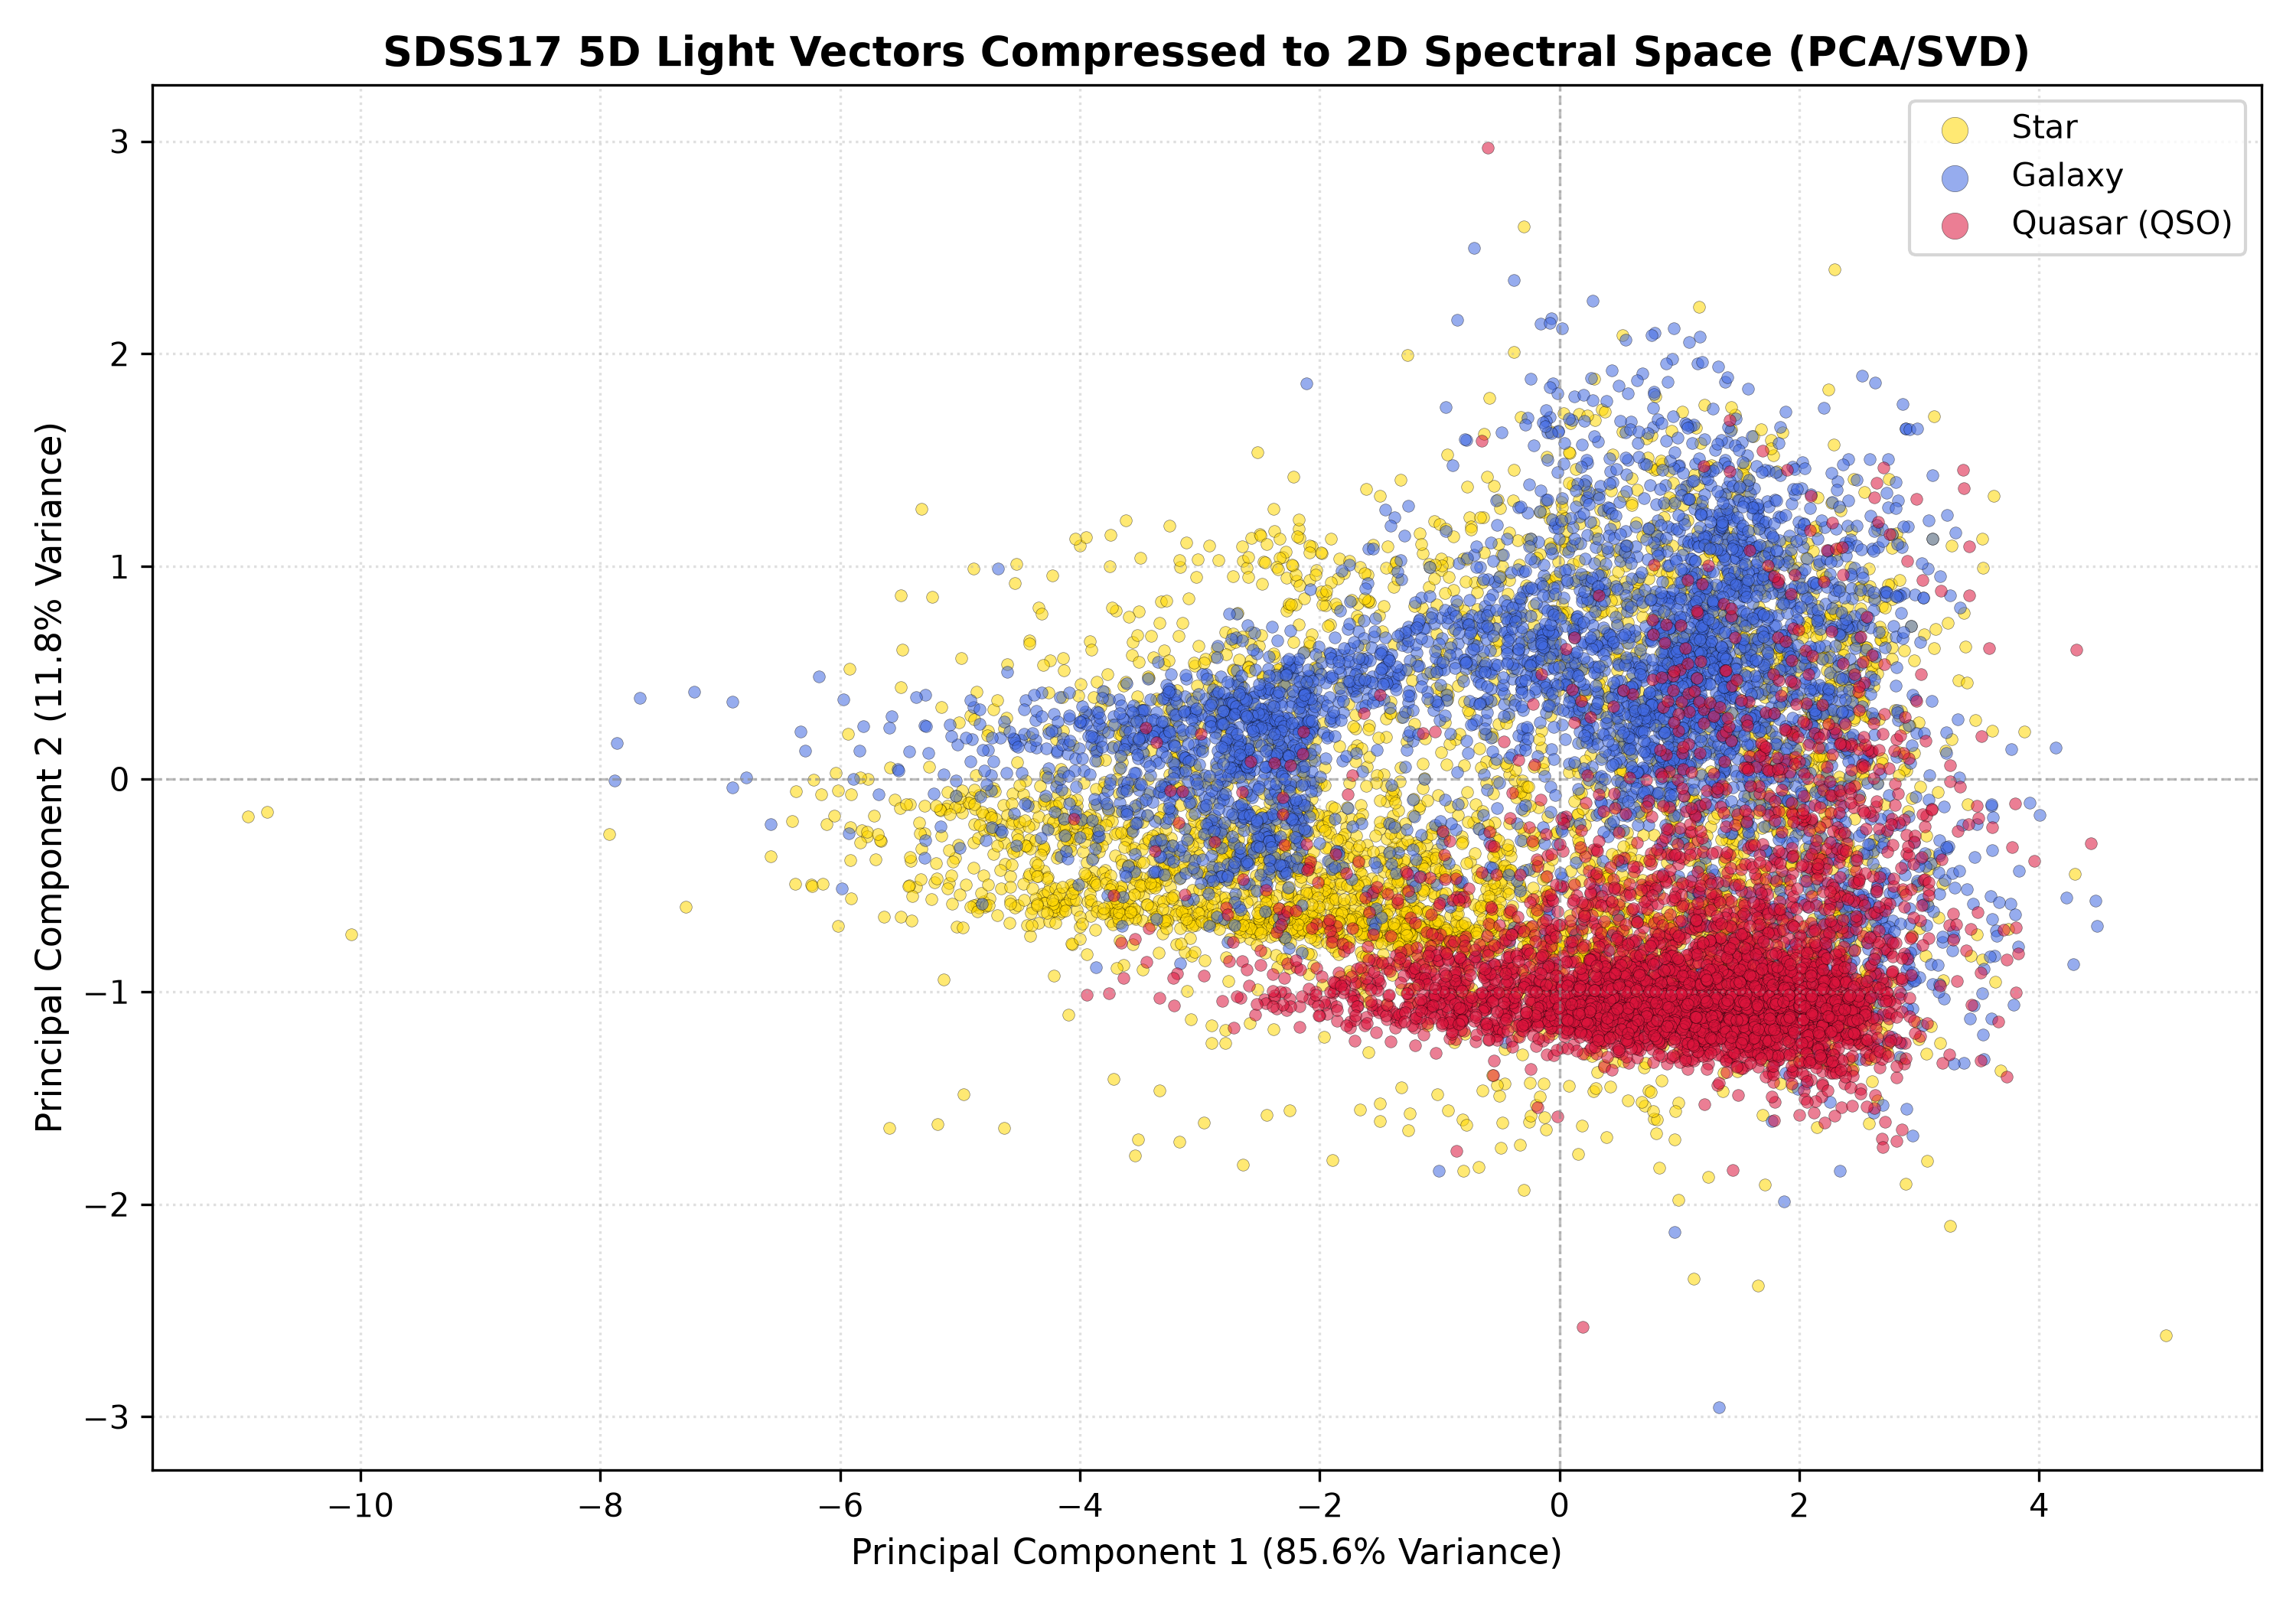

In [ ]:
from pathlib import Path
from IPython.display import display, Image, Markdown

figures_dir = Path("../figures")
png_files = sorted(figures_dir.glob("*.png"))

if not png_files:
    print("No PNG figures found in ../figures/")
else:
    print(f"Displaying {len(png_files)} exported figures:\n")
    for img_path in png_files:
        display(Markdown(f"### `{img_path.name}`"))
        display(Image(filename=str(img_path), width=750))

## Final Conclusion
Returning to our unifying question—*using only five raw photometric brightness readings ($u, g, r, i, z$), can pure math tell us both what a celestial object is and how fast it is moving?*—our four-phase pipeline demonstrates both the power and the physical boundaries of linear methods on real SDSS17 telescope data:

* **Half 1 — Identity from Geometry (Phases 2 & 3):** Compressing the 5D spectral vector space into 2D via PCA/SVD retains **97.4% of total variance** (`PC1: 85.6%`, `PC2: 11.8%`), proving that celestial light spectra occupy a structured low-dimensional subspace. Unsupervised K-Means ($k=3$) then tests how cleanly that geometry separates Stars, Galaxies, and Quasars without labels.
* **Half 2 — Motion from Light (Phases 1 & 4):** Linear Regression trained on `u, g, r, i, z` establishes an honest linear baseline ($R^2 = 0.2789$, $\text{RMSE} = 0.6210$ for redshift; $R^2 = 0.2016$, $\text{RMSE} = 0.2384c$ for velocity). Passing predictions through Einstein's SymPy-derived Relativistic Doppler equation strictly bounds every velocity below the speed of light ($c = 1.0$), while the scatter on zero-redshift Stars and high-redshift Quasars ($z > 2$) pinpoints the exact physical limit of a linear hyperplane on non-linear astrophysical spectra.